In [8]:
import pandas as pd
import numpy as np
import xarray as xr
import scipy
import glob
import pathlib
import matplotlib.pyplot as plt
import matplotlib as mpl
import string
letters = string.ascii_lowercase
import helpers
import plot_helpers

extra_figs = pathlib.Path(f'/work/bb1153/b382635/plots/model_paper/grl_resubmission/figures/paper_supporting')
extra_figs.mkdir(parents=1, exist_ok=1)

CMAP = mpl.colors.ListedColormap(plt.get_cmap('Reds')(np.linspace(.25,1,265)))
HCMAP = mpl.colors.ListedColormap(plt.get_cmap("cividis")(np.linspace(0.25, 1, 256)))
dpi = 300
ext = 'pdf'
fs = 12

global_labels = {"total_CMT":r"$\int M_c dt\,$ [kg]",
                 "total_CMT_l60":r"$\int M_c dt\,$",
                 "max_CMT":r"$M_{c,max}$",
                 "max_CMF":r"$(\rho w)_{max}$",
                 "mean_CMF":r"$(\rho w)_{mean}$ [kg m$^{-2}$ s$^{-1}$]",
                 "max_w":r"$w_{max}$ [m s$^1$]",
                 "col_max_w":r"$w_{max}$",
                 "max_Ac":r"$A_c$ [m$^2$]",
                 "core_max_pr":r"$pr_{max}$ [kg m$^{-2}$ s$^{-1}$]",
                 "cloud_min_tt": r"$T_{b,min}$ [K]",
                 "conv_lifetime":r"$t_c$ [hr]",
                 "ncores":"Cores",
                 "Apred_v1":r'$\frac{1}{D\bar{\rho}}\int M_{c,max}\,dt$',
                 "Apred_v2":r'$\int \frac{M_c}{D\bar{\rho}}\,dt$',
                }


#### IWP DISTRIBUTION

This study assessed a series of IWP thresholds, here we review the distribution of anvil IWP in the deep convective clouds.

In [2]:
# load data

datadir = pathlib.Path(f'/work/bb1153/b382635/plots/model_paper/grl_resubmission/data/statistics_IWP')
ds_flist = sorted(list(datadir.glob('*.nc')))
li = []
for i in range(len(ds_flist)):
    ds = xr.open_dataset(ds_flist[i])
    li.append(ds)
ds_iwp = xr.concat(li, dim='system')

In [3]:
# estimate percentiles from histogram

nbins = np.linspace(1e-3, 1e2, 200)
lbins = np.logspace(np.log10(1e-3), np.log10(1e2), 100)

percentiles = np.arange(0, 1.0, 0.05)
pi_values = pd.DataFrame(index=percentiles)

var = "anvil_fwp_lhist"
counts = ds_iwp[var].sum("system")
edges = np.log10(lbins)

cdf = counts.cumsum().values
cdf = cdf / cdf[-1]

pi_values[var] = np.interp(
    percentiles,
    cdf,
    edges[1:],
)
if not counts.dims[0] == "nbins":
    pi_values[var] = 10**pi_values[var]

pi_values.index.name = "percentile"
pi_values.index = pi_values.index.round(2)
pi_values = pi_values.loc[:,var]

# pi_values.to_csv('/home/b/b382635/s/my_notebooks/model_paper/grl_resubmission/scripts/iwp_percentiles.csv')

In [4]:
pi_values

percentile
0.00    0.001123
0.05    0.027823
0.10    0.042447
0.15    0.059324
0.20    0.076843
0.25    0.096375
0.30    0.118447
0.35    0.143737
0.40    0.173084
0.45    0.207716
0.50    0.249198
0.55    0.299618
0.60    0.362519
0.65    0.442695
0.70    0.548039
0.75    0.691038
0.80    0.895221
0.85    1.205763
0.90    1.716117
0.95    2.728239
Name: anvil_fwp_lhist, dtype: float64

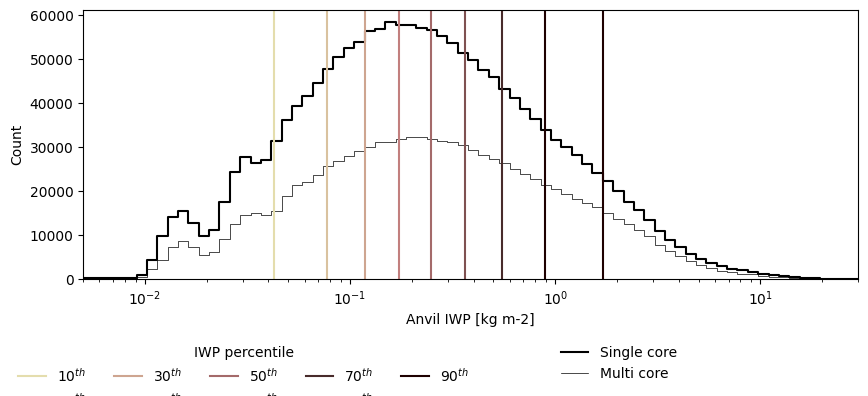

In [28]:
# view

fig, ax = plt.subplots(figsize=(10,3.5))

# d = ds_iwp.anvil_fwp_lhist.dropna('system')
# y = (d.sum("system"))# / d.system.size)
# y.plot.step(ax=ax, c='k', )

d = ds_iwp.where(ds_iwp.ncores==1).anvil_fwp_lhist.dropna('system')
y = (d.sum("system") )#/ d.system.size)
y.plot.step(ax=ax, c='k', lw=1.5)
# ax.fill_between(y.coords[y.dims[0]], y, step='pre', color=c1, alpha=.15)

d = ds_iwp.where(ds_iwp.ncores>1).anvil_fwp_lhist.dropna('system')
y = (d.sum("system"))# / d.system.size)
y.plot.step(ax=ax, c='k', lw=.5)
# ax.fill_between(y.coords[y.dims[0]], y, step='pre', color=c2, alpha=.15)

ax.set_xlabel('Anvil IWP [kg m-2]')
ax.set_ylabel('Count')
ax.set_xscale('log')
# ax.grid()

cmap = mpl.colors.ListedColormap(plt.get_cmap('pink_r')(np.linspace(.2,1.256)))
for pi in pi_values.index[2::2]:
    ax.axvline(pi_values[pi], c=cmap(pi), label=f"{pi:.2}")
# ax.axvline(0.2, ls=':', c='k', lw=2, label="Sokol '24 & Gasparini '19")
ax.set_xlim(5e-3,3e1)
ax.set_ylim(0,None)

# legends

l1_handles = [mpl.lines.Line2D([], [], color=cmap(pi), label=f"{pi*100:.0f}"+"$^{th}$") for pi in pi_values.index[2::2]]
l1 = ax.legend(handles=l1_handles, title="IWP percentile", loc='upper left', bbox_to_anchor=(-.1, -.2), ncol=5, frameon=0)
ax.add_artist(l1)

l2_handles = [
    # mpl.lines.Line2D([], [], color='k', lw=2, label='All DCCs'),
    mpl.lines.Line2D([], [], color='k', lw=1.5, label='Single core'),
    mpl.lines.Line2D([], [], color='k', lw=.5, label='Multi core'),
    # mpl.lines.Line2D([], [], color='k', ls=':', lw=2, label="Sokol '24 & Gasparini '19"),
]
l2 = ax.legend(handles=l2_handles, loc='upper left', bbox_to_anchor=(.6, -.2), frameon=0)

fig.savefig(extra_figs / f'iwp_distribution.{ext}', bbox_inches='tight', dpi=dpi, bbox_extra_artists=[l1, l2],)

#### LOAD MORE DATA

In [9]:
# load
datadir = pathlib.Path(f'/work/bb1153/b382635/plots/model_paper/grl_resubmission/data/statistics_L2')
ds_flist = sorted(list(datadir.glob('*.nc')))
li = []
for i in range(len(ds_flist)):
    ds = xr.open_dataset(ds_flist[i])
    li.append(ds)
ds_all = xr.concat(li, dim='system')

# filter
gsystems = ds_all.max_CMF.dropna('system').system
ds_good = ds_all.sel(system=gsystems)
ds = ds_good.where(ds_good.lifestages_valid).dropna('system', how='all')

In [10]:
df_metrics = helpers.dccs_by_intensity_metrics(ds, ds[['total_CMT',]])

#### FRACTIONAL COVERAGE

How much coverge does each DCC type represent?

In [53]:
net_area_single = ds.total_cloud_area.where(ds.ncores==1).sum().item()
net_area_multi = ds.total_cloud_area.where(ds.ncores>1).sum().item()

net_area_single / net_area_multi

1.8717794455677277

#### LIFESTAGE DURATION
Assess the typical durations of each cloud lifestage

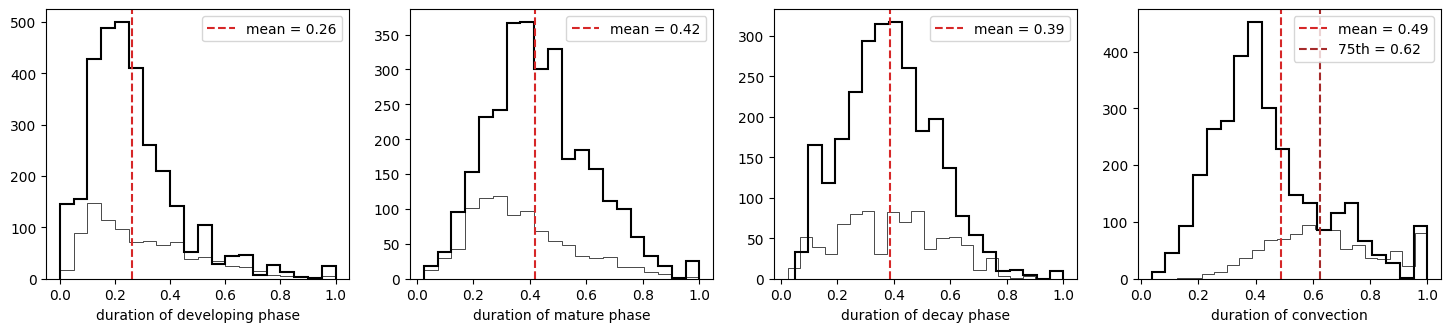

In [27]:
fig, axs = plt.subplots(1,4, figsize=(18, 3.5))

params = dict(ec="k", fc='none', bins=20, histtype='step', )

plots = [
    (ds.t_max_depth, "duration of developing phase"),
    ((ds.t_max_area - ds.t_max_depth).where(lambda x: x > 0), "duration of mature phase"),
    ((1 - ds.t_max_area).where(lambda x: x > 0), "duration of decay phase"),
    (ds.conv_lifetime / ds.lifetime, "duration of convection"),
]

for ax, (d, xlabel) in zip(axs, plots):
    d.where(ds.ncores==1).plot.hist(ax=ax, lw=1.5, **params)
    d.where(ds.ncores>1).plot.hist(ax=ax, lw=.5, **params)

    mean = d.mean()
    median = d.median()

    ax.axvline(mean, c="tab:red", ls="--", label=f"mean = {mean.item():.2f}", lw=1.5)
    # ax.axvline(median, c="tab:blue", ls="--", label=f"median = {median.item():.2f}")

    if xlabel=="duration of convection":
        ax.axvline(d.quantile(.75), c="brown", ls="--", lw=1.5, label=f"75th = {d.quantile(.75).item():.2f}")

    ax.set_xlabel(xlabel)
    ax.legend()
    # ax.grid()

fig.savefig(extra_figs / f'lifestage_durations.{ext}', bbox_inches='tight', dpi=dpi)

#### CMF DISTRIBUTION
This study assessed CMF quantiles, here we reveiw the distribution of cloud CMF

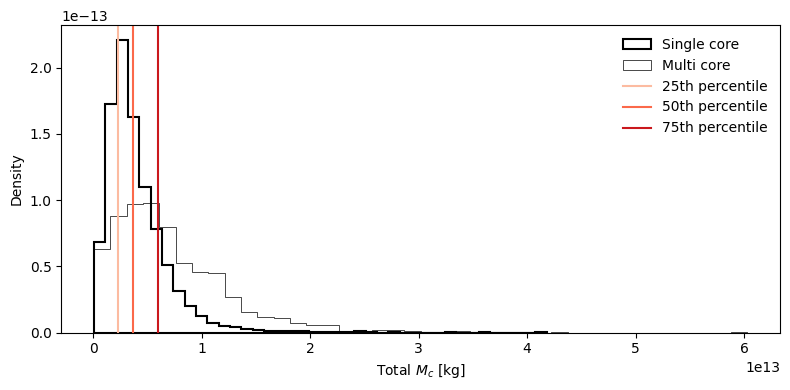

In [30]:
# data

fig, ax = plt.subplots(figsize=(8,4), layout="tight")
hist_params = dict(bins=40, density=True, histtype="stepfilled", alpha=1, fc="none", )

# histograms
# ds.total_CMT.plot.hist(ax=ax, lw=2, ec='k', **hist_params, label='All DCCs')
ds.where(ds.ncores==1).total_CMT.plot.hist(ax=ax, lw=1.5, ec='k', **hist_params, label='Single core')
ds.where(ds.ncores>1).total_CMT.plot.hist(ax=ax, lw=.5, ec='k', **hist_params, label='Multi core')

# quantiles
quantiles = ds.total_CMT.quantile([0.25, 0.5, 0.75]).rename({"quantile":"pi"})

for i, q in enumerate(quantiles.pi.values):
    ax.axvline(
        quantiles.sel(pi=q),
        color=CMAP(i / len(quantiles)),
        lw=1.5,
        ls='-',
        label=f"{int(100 * q)}th percentile",
    )

ax.set_xlabel("Total $M_c$ [kg]")
ax.set_ylabel("Density")
ax.legend(frameon=False)
# ax.grid()

fig.savefig(extra_figs / f'total_Mc_quartiles.{ext}', bbox_inches='tight', dpi=dpi)

#### CLOUD RESPONSE OF RELATED VARIABLES
Assess the cloud response to total convective mass flux for two related variables, total anvil condensate and anvil horizontal divergence

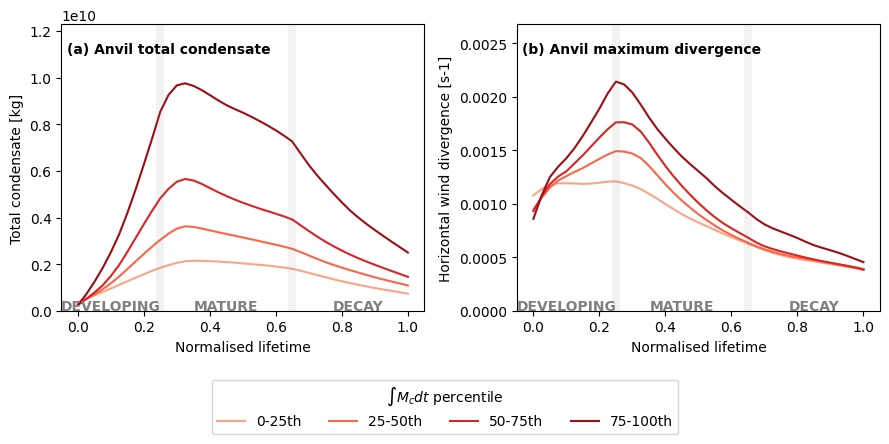

In [59]:
# data
cloud_variables = ["anvil_tw", "anvil_div_max"]

# mean evolution by percentile bin
pdata = helpers.group_dataset_by_intensity(ds[cloud_variables], df_metrics, apply=lambda x: x.mean("system", keep_attrs=True),)["total_CMT"]

# figure
N = len(cloud_variables)
fig, axs = plt.subplots(1,N, figsize=(N * 4.5, 3.75), layout="tight")
axs = np.atleast_1d(axs)

plot_titles = ["Anvil total condensate", "Anvil maximum divergence"]
plot_ylabels = ["Total condensate", "Horizontal wind divergence"]
legend_handles, legend_labels = None, None

for i, var in enumerate(cloud_variables):
    ax = axs[i]

    for j, b in enumerate(pdata.bins.values):
        color = CMAP(j / 4 + 0.1)
        evolution = plot_helpers.get_evolution(pdata[var].sel(bins=b))
        evolution.plot(ax=ax, c=color, label=f"{b}th", zorder=1, lw=1.5)

    plot_helpers.show_phases(ax, y=ax.get_ylim()[1] * 0.05)

    ax.text(
        0.015,
        0.9,
        f"({letters[i]}) {plot_titles[i]}",
        c="k",
        weight="bold",
        transform=ax.transAxes,
    )

    ax.set_xlabel("Normalised lifetime")
    ax.set_ylabel(f"{plot_ylabels[i]} [{ds[var].units}]")
    ax.set_title(None)

    ax.set_ylim(0, ax.get_ylim()[1] * 1.2)

    if legend_handles is None:
        legend_handles, legend_labels = ax.get_legend_handles_labels()

legend = fig.legend(
    legend_handles,
    legend_labels,
    title=r"$\int M_c dt$ percentile",
    loc="center",
    bbox_to_anchor=(0.5, -0.1),
    ncol=4,
    frameon=True,
)

fig.savefig(extra_figs / f'cloud_response_water_and_wind.{ext}', bbox_inches='tight', dpi=dpi)

#### PROCESSES DRIVING CMF
Supporting information for the paper, this result tests which convective processes are most well correlated to the CMF to which they each contribute

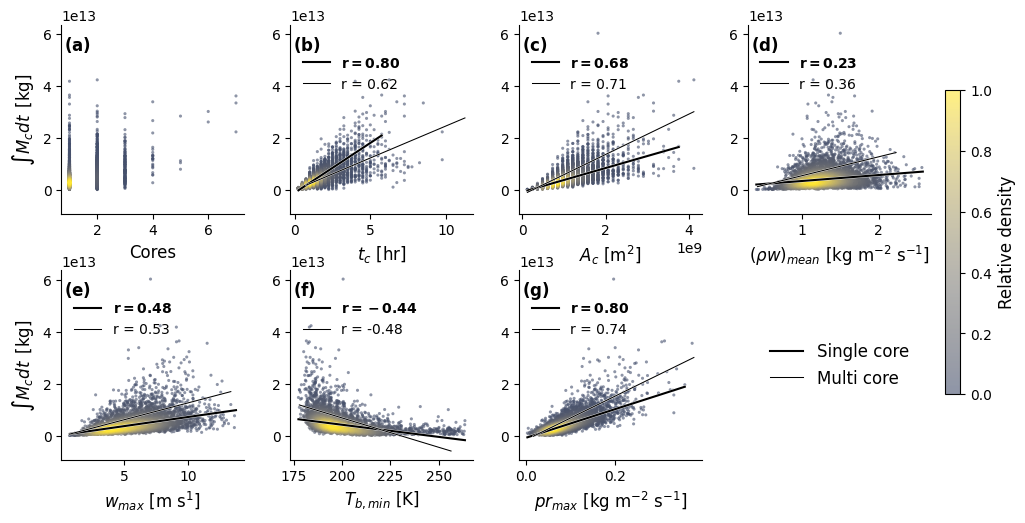

In [11]:
fig = plt.figure(figsize=(10, 5))

grid = (2, 4)
nrows, ncols = grid
axs = [None] * (nrows * ncols)

gs = mpl.gridspec.GridSpec(nrows, ncols, figure=fig, hspace=0.3, wspace=0.25,
                           left=0.08, right=0.95, top=0.95, bottom=0.08)

for i in range(nrows * ncols):
    sharey = axs[0] if i > 0 else None
    axs[i] = fig.add_subplot(gs[i // ncols, i % ncols], sharey=sharey)

metrics = ["ncores", "conv_lifetime", "max_Ac", "mean_CMF", "max_w", "cloud_min_tt", "core_max_pr"]
ylab = global_labels['total_CMT']
params = dict(low=0, high=99.95)

for i, metric in enumerate(metrics):
    ax = axs[i]
    x, y = ds[metric], ds["total_CMT"]

    result, sc, _ = plot_helpers.plot_relationship(ax, x, y, cmap=HCMAP, **params, line=False)

    for pds, lw in zip([ds.where(ds.ncores==1), ds.where(ds.ncores>1)], [1.5, .75]):
        if metric == "ncores":
            continue
        x, y = pds[metric], pds["total_CMT"]
        result, _, _ = plot_helpers.plot_relationship(ax, x, y, scale='linear', line_kw={'lw': lw}, **params, scatter=False, density=False)

        r, p, s = result.rvalue, result.pvalue, result.slope
        text = rf"$\mathbf{{r={r:.2f}}}$" if lw > 1 else rf"r = {r:.2f}"
        if p > 0.05:
            print('NSS')
        ax.plot([], [], c='k', lw=lw, label=text)

    ax.set_xlabel(global_labels[metric], fontsize=fs)
    plot_helpers.panel_label(ax, letters[i], '', fs=fs)
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, .9), fontsize=fs-2)
    ax.spines[["top", "right"]].set_visible(False)

axs[0].set_ylabel(ylab, fontsize=fs)
axs[4].set_ylabel(ylab, fontsize=fs)

ax_leg = axs[-1]
ax_leg.axis('off')
legend_elements = [
    mpl.lines.Line2D([], [], c='k', lw=1.5, label='Single core'),
    mpl.lines.Line2D([], [], c='k', lw=0.75, label='Multi core'),
]
ax_leg.legend(handles=legend_elements, frameon=False, fontsize=fs,
              loc='center', bbox_to_anchor=(0.5, 0.5))

fig.canvas.draw()
full_height = axs[ncols-1].get_position().y1 - axs[-2].get_position().y0
scaled_height = full_height * 0.7
mid_y = (axs[ncols-1].get_position().y1 + axs[-2].get_position().y0) / 2
cax = fig.add_axes([axs[ncols-1].get_position().x1 * 1.015, mid_y - scaled_height / 2, 0.015, scaled_height])
cb = fig.colorbar(sc, cax=cax)
cb.set_label('Relative density', fontsize=fs)

fig.savefig(extra_figs / f"figS03.{ext}", bbox_inches="tight", dpi=dpi, transparent=True)

#### PROCESSES DRIVING CMF->A_max

An extension to figure 3, this result tests the relationship between different convective processes and A_max

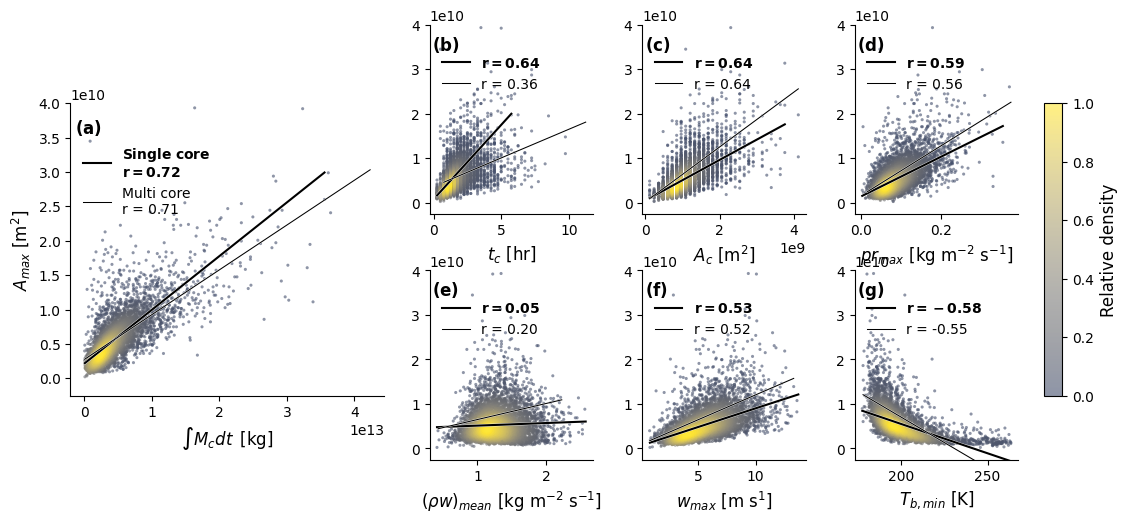

In [12]:
fig = plt.figure(figsize=(12, 5))

grid = (2, 3)
nrows, ncols = grid
axs = [None] * (1 + nrows * ncols)

outer = mpl.gridspec.GridSpec(1, 2, figure=fig, wspace=0.1, width_ratios=[0.8, 1.5],
                              left=0.08, right=0.87, top=0.95, bottom=0.08)

left_gs = outer[0].subgridspec(3, 1, height_ratios=[.215, .8, .175], hspace=0)
axs[0] = fig.add_subplot(left_gs[1])
inner = outer[1].subgridspec(nrows, ncols, hspace=0.3, wspace=0.3)
for i in range(nrows * ncols):
    sharey = axs[1] if i > 0 else None
    axs[i + 1] = fig.add_subplot(inner[i // ncols, i % ncols], sharey=sharey)

metrics = ["total_CMT", "conv_lifetime", "max_Ac", "core_max_pr", "mean_CMF", "max_w", "cloud_min_tt"]
ylab = "$A_{max}$ [m$^2$]"
params = dict(low=0, high=99.95)

right_axs = []
for i,ax in enumerate(axs):
    metric = metrics[i]
    x, y = ds[metric], ds["max_anvil_area"]

    result, sc, _ = plot_helpers.plot_relationship(ax, x, y, cmap=HCMAP, **params, line=False)

    for pds, lw, label in zip([ds.where(ds.ncores==1), ds.where(ds.ncores>1)], [1.5,.75], ['l','l']):
        x, y = pds[metric], pds["max_anvil_area"]
        result, _, _ = plot_helpers.plot_relationship(ax, x, y, scale='linear', line_kw={'lw':lw}, **params, scatter=False, density=False)
    
        r, p, s = result.rvalue, result.pvalue, result.slope
        text = rf"$\mathbf{{r={r:.2f}}}$" if lw > 1 else rf"r = {r:.2f}"
        if p > 0.05:
            print('NSS')
        if i==0:
            text = rf"$\mathbf{{Single}}$ $\mathbf{{core}}$" + f"\n{text}" if lw>1 else f"Multi core\n{text}"
        ax.plot([], [], c='k', lw=lw, label=text)
    
    ax.set_xlabel(global_labels[metric], fontsize=fs)
    plot_helpers.panel_label(ax, letters[i], '', fs=fs)
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0,.9), fontsize=fs-2)
    ax.spines[["top","right"]].set_visible(False)
    ax.set_ylim(-0.25e10, 4e10)

axs[0].set_ylabel(ylab, fontsize=fs)

fig.canvas.draw()
pos = axs[0].get_position()
cax = fig.add_axes([axs[-1].get_position().x1*1.025, pos.y0, 0.015, pos.height])
cb = fig.colorbar(sc, cax=cax)
cb.set_label('Relative density', fontsize=fs)

fig.savefig(extra_figs / f"figS04.{ext}", bbox_inches="tight", dpi=dpi, transparent=True)


#### ADDIDITIONAL CORRELATION SCORES

In [114]:
subsets = {
    'All':         ds,
    'Single core': ds.where(ds.ncores == 1, drop=True),
    'Multi core':  ds.where(ds.ncores  > 1, drop=True),
}
metrics = ["total_CMT", "conv_lifetime", "max_Ac", "mean_CMF", "max_w"]
thresholds = {4: '>50th IWP', 8: '>75th IWP'}

rows = []
for thresh, thresh_label in thresholds.items():
    for metric in metrics:
        for subset_label, subset in subsets.items():
            x = subset[metric].values
            y = (subset["total_thick_area"].isel(threshold=thresh) / subset["max_anvil_area"]).values
            mask = np.isfinite(x) & np.isfinite(y)
            r, p = scipy.stats.pearsonr(x[mask], y[mask])
            rows.append(dict(threshold=thresh_label,
                metric=metric,
                subset=subset_label,
                r=r.round(2),
                significant=p < 0.05,
            ))

df = pd.DataFrame(rows)
df.set_index(['threshold','subset'])

metric     r  significant
threshold subset                                       
>50th IWP All              total_CMT  0.46         True
          Single core      total_CMT  0.35         True
          Multi core       total_CMT  0.45         True
          All          conv_lifetime  0.61         True
          Single core  conv_lifetime  0.45         True
          Multi core   conv_lifetime  0.61         True
          All                 max_Ac  0.20         True
          Single core         max_Ac  0.16         True
          Multi core          max_Ac  0.21         True
          All               mean_CMF -0.18         True
          Single core       mean_CMF -0.21         True
          Multi core        mean_CMF -0.05        False
          All                  max_w  0.01        False
          Single core          max_w -0.02        False
          Multi core           max_w  0.03        False
>75th IWP All              total_CMT  0.47         True
          Single core      total_CMT  0.41         True
          Multi core       total_CMT  0.41         True
          All          conv_lifetime  0.59         True
          Single core  conv_lifetime  0.51         True
          Multi core   conv_lifetime  0.53         True
          All                 max_Ac  0.16         True
          Single core         max_Ac  0.14         True
          Multi core          max_Ac  0.13         True
          All               mean_CMF -0.02        False
          Single core       mean_CMF -0.00        False
          Multi core        mean_CMF  0.02        False
          All                  max_w -0.07         True
          Single core          max_w -0.08         True
          Multi core           max_w -0.10         True

#### SENSTIVITY TO ABH
The definition of the anvil base height is made using the profile of condensate of each particular DCC, here we assess the senstivity of results to that definition

##### 1. Does the position of the ABH make physical sense?

In [122]:
# load data

datadir = pathlib.Path(f'/work/bb1153/b382635/plots/model_paper/grl_resubmission/data/statistics_ABH')
ds_flist = sorted(list(datadir.glob('*.nc')))
li = []
for i in range(len(ds_flist)):
    ds = xr.open_dataset(ds_flist[i])
    li.append(ds)
ds_abh = xr.concat(li, dim='system')

gsystems = ds_all.max_CMF.dropna('system').system
ds_good = ds_all.sel(system=gsystems)
ds_abh = ds_abh.where(ds_good.lifestages_valid).dropna('system', how='all')

In [123]:
import metpy.calc as mpcalc
from metpy.units import units

el_z_per_system  = np.full(ds_abh.sizes['system'], np.nan)
lfc_z_per_system = np.full(ds_abh.sizes['system'], np.nan)

for i in range(ds_abh.sizes['system']):
    p_i  = ds_abh.env_p.isel(system=i).values[::-1] * units.Pa
    T_i  = ds_abh.env_T.isel(system=i).values[::-1] * units.kelvin
    rh_i = ds_abh.env_rh.isel(system=i).values[::-1] * 100 * units.percent
    Td_i = mpcalc.dewpoint_from_relative_humidity(T_i, rh_i)
    pp_i = mpcalc.parcel_profile(p_i, T_i[0], Td_i[0])
    el_p_i, _  = mpcalc.el(p_i,  T_i, Td_i, pp_i)
    lfc_p_i, _ = mpcalc.lfc(p_i, T_i, Td_i, pp_i)

    zg_i = ds_abh.env_zg.isel(system=i).values[::-1]
    sort_idx = np.argsort(p_i.magnitude)
    p_s, zg_s = p_i.magnitude[sort_idx], zg_i[sort_idx]

    el_z_per_system[i] = np.interp(el_p_i.magnitude, p_s, zg_s) / 1e3
    lfc_z_per_system[i] = np.interp(lfc_p_i.magnitude, p_s, zg_s) / 1e3

ds_abh['el']  = xr.DataArray(el_z_per_system,  dims='system',)
ds_abh['lfc'] = xr.DataArray(lfc_z_per_system, dims='system',)

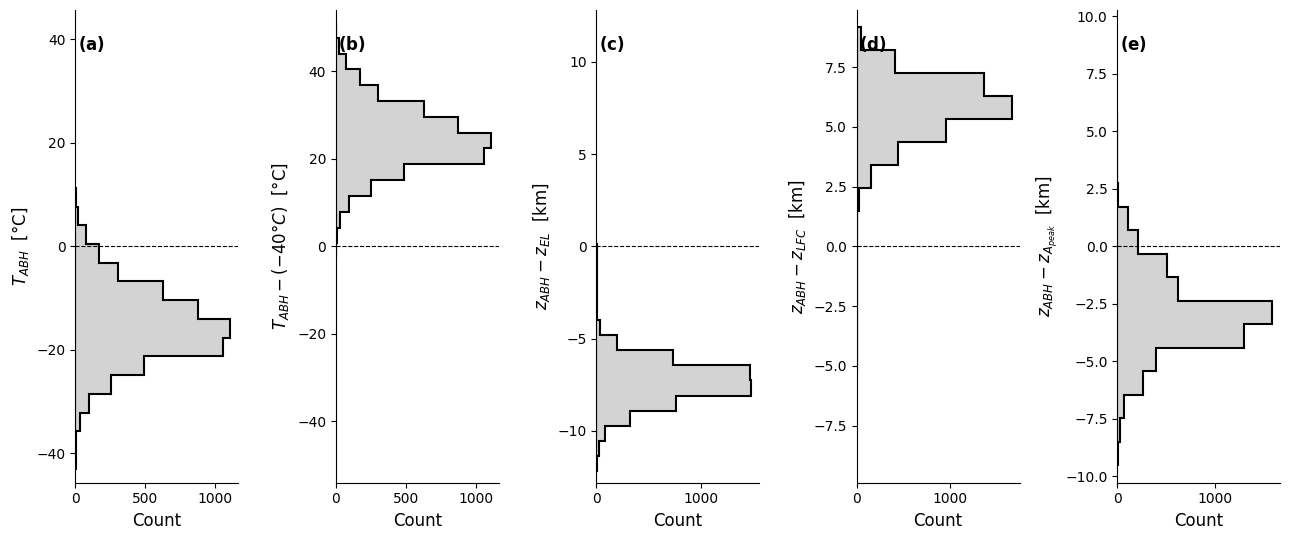

In [125]:
def height_diff(da_a, da_b, zg, lev_dim='level_full'):
    def to_height(x):
        if isinstance(x, xr.DataArray) and lev_dim in x.dims:
            return zg.sel({lev_dim: x}, method='nearest')
        else:
            return zg.sel({lev_dim: x}, method='nearest')
    return (to_height(da_a) - to_height(da_b)) / 1e3

fig, axs = plt.subplots(1,5, figsize=(13,5.5))
axs = axs.flat

hparams = dict(bins=15, histtype='stepfilled', fc='lightgrey', ec='k', lw=1.5, orientation='horizontal')
lev = ds_abh.ABH
zg  = ds_abh.env_zg

def profile_peak_level(da, lev_dim='level_full'):
    return da.idxmax(lev_dim, skipna=True)

def profile_min_level(da, lev_dim='level_full'):
    return da.idxmin(lev_dim, skipna=True)

def plot_panel(ax, d_raw, ylabel):
    d = d_raw.ravel() if hasattr(d_raw, 'ravel') else np.array(d_raw)
    d = d[np.isfinite(d)]
    ax.hist(d, **hparams)
    ax.set_ylabel(ylabel, fontsize=fs)

ax = axs[0]
T_at_abh = ds_abh.env_T.sel(level_full=lev, method='nearest') - 273.15
plot_panel(ax, T_at_abh.values, '$T_{ABH}$  [°C]')

ax = axs[1]
plot_panel(ax, (T_at_abh + 40).values, '$T_{ABH} - (-40°C)$  [°C]')

ax = axs[4]
area_peak_lev = profile_peak_level(ds_abh.cloud_area_z)
plot_panel(ax, height_diff(lev, area_peak_lev, zg).values,
           r'$z_{ABH} - z_{A_{peak}}$  [km]')

ax = axs[2]
plot_panel(ax, (abh_z - ds_abh.el).values,
           r'$z_{ABH} - z_{EL}$  [km]')

ax = axs[3]
plot_panel(ax, (abh_z - ds_abh.lfc).values,
           r'$z_{ABH} - z_{LFC}$  [km]')

for i, ax in enumerate(axs):
    ax.axhline(0, lw=0.8, c='k', ls='--')
    ylim = ax.get_ylim()
    max_abs = max(abs(ylim[0]), abs(ylim[1]))
    ax.set_ylim(-max_abs, max_abs)
    ax.set_xlabel('Count', fontsize=fs)
    ax.spines[["top", "right"]].set_visible(False)
    plot_helpers.panel_label(ax, letters[i], fs=fs)

fig.tight_layout()
fig.savefig(extra_figs / f"figS01.{ext}", bbox_inches="tight", dpi=dpi, transparent=True)

##### 2. Are the results senstive to edge cases in ABH?

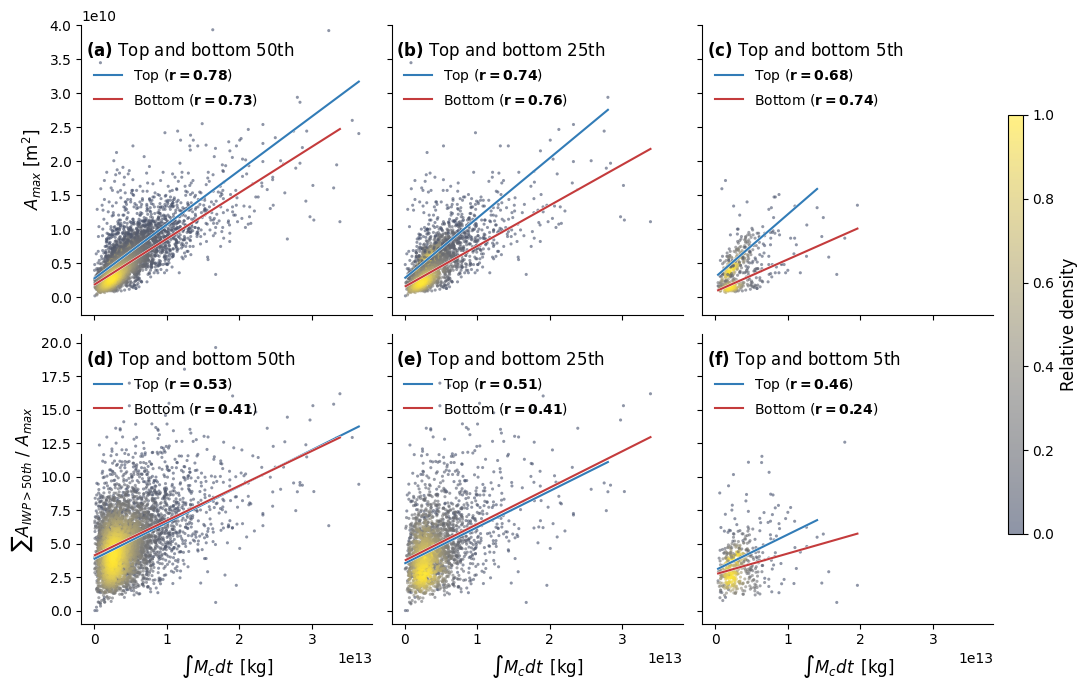

In [13]:
fig, axs = plt.subplots(2,3, figsize=(10,7), sharey='row', sharex=True)

abh_median = ds.ABH.median()
splits_v1 = {
    'Top':  ds.where(ds.ABH < abh_median),
    'Bottom': ds.where(ds.ABH >= abh_median),
}

abh_q25 = ds.ABH.quantile(0.25)
abh_q75 = ds.ABH.quantile(0.75)
splits_v2 = {
    'Top':    ds.where(ds.ABH <= abh_q25),
    'Bottom': ds.where(ds.ABH >= abh_q75),
}

abh_p05 = ds.ABH.quantile(0.05)
abh_p95 = ds.ABH.quantile(0.95)
splits_v3 = {
    'Top':     ds.where(ds.ABH <= abh_p05),
    'Bottom': ds.where(ds.ABH >= abh_p95),
}

cmap_abh = plt.get_cmap('RdBu_r')
colors = [cmap_abh(0.15), cmap_abh(0.85)]
params = dict(low=0, high=99.95)

split_configs = [
    (splits_v1, 'Top and bottom 50th'),
    (splits_v2, 'Top and bottom 25th'),
    (splits_v3, 'Top and bottom 5th'),
]

row_configs = [
    dict(y_fn=lambda pds: pds["max_anvil_area"],
         ylabel="$A_{max}$ [m$^2$]",
         ylim=(-0.25e10, 4e10),),
    dict(y_fn=lambda pds: pds["total_thick_area"].isel(threshold=4) / pds.max_anvil_area,
         ylabel=r"$\sum A_{IWP>50th}$ / $A_{max}$",
         ylim=None,),
]

i = 0
for row, (row_cfg, row_axs) in enumerate(zip(row_configs, axs)):
    for col, (ax, (splits, version_title)) in enumerate(zip(row_axs, split_configs)):
        for (label, pds), c in zip(splits.items(), colors):
            x = pds["total_CMT"]
            y = row_cfg['y_fn'](pds)

            result, sc, _ = plot_helpers.plot_relationship(ax, x, y, cmap=HCMAP, **params,
                                                           line_kw={'c': c}, scatter=False, density=False)
            result, sc, _ = plot_helpers.plot_relationship(ax, x, y, cmap=HCMAP, **params,
                                                           line=False)

            r, p, s = result.rvalue, result.pvalue, result.slope
            r_text = rf"$\mathbf{{r={r:.2f}}}$" if p < 0.05 else rf"r={r:.2f}"
            ax.plot([], [], c=c, lw=1.5, label=f"{label} ({r_text})")

        if row == 1:
            ax.set_xlabel(global_labels['total_CMT'], fontsize=fs)
        ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, .9), fontsize=fs-2)
        ax.spines[["top", "right"]].set_visible(False)
        plot_helpers.panel_label(ax, letters[i], version_title, fs=fs)
        if row_cfg['ylim']:
            ax.set_ylim(*row_cfg['ylim'])
        if col > 0:
            ax.tick_params(labelleft=False)
        i += 1

    row_axs[0].set_ylabel(row_cfg['ylabel'], fontsize=fs)

fig.canvas.draw()
fig.tight_layout()

fig.canvas.draw()
pos_tr = axs[0, 2].get_position()
pos_br = axs[1, 2].get_position()
full_height = pos_tr.y1 - pos_br.y0
scaled_height = full_height * 0.7
mid_y = (pos_tr.y1 + pos_br.y0) / 2
cax = fig.add_axes([pos_tr.x1 * 1.015, mid_y - scaled_height / 2, 0.015, scaled_height])
cb = fig.colorbar(sc, cax=cax)
cb.set_label('Relative density', fontsize=fs)

fig.savefig(extra_figs / f"figS02.{ext}", bbox_inches="tight", dpi=dpi, transparent=True)

#### LAND/OCEAN
Here we explore whether the results of this study vary between land and ocean

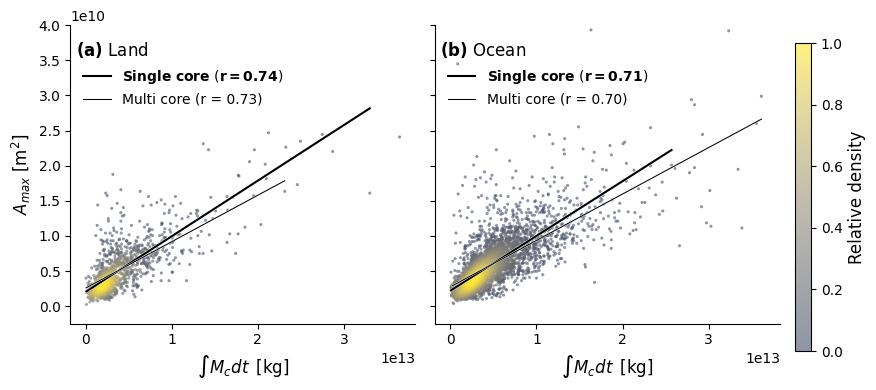

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(8, 4), sharey=True, sharex=True)

ds_land  = ds.where(ds.ocean_fraction < 0.5)
ds_ocean = ds.where(ds.ocean_fraction >= 0.5)
titles = ['Land', 'Ocean']
params = dict(low=0, high=99.95)

for i, (ax, pds_env, title) in enumerate(zip(axs, [ds_land, ds_ocean], titles)):
    x, y = pds_env["total_CMT"], pds_env["max_anvil_area"]

    result, sc, _ = plot_helpers.plot_relationship(ax, x, y, cmap=HCMAP, **params, line=False)

    for pds, lw in zip([pds_env.where(pds_env.ncores==1), pds_env.where(pds_env.ncores>1)], [1.5, 0.75]):
        x, y = pds["total_CMT"], pds["max_anvil_area"]
        result, _, _ = plot_helpers.plot_relationship(ax, x, y, scale='linear', line_kw={'lw': lw},
                                                      **params, scatter=False, density=False)

        r, p, s = result.rvalue, result.pvalue, result.slope
        text = rf"($\mathbf{{r={r:.2f}}}$)" if lw > 1 else rf"(r = {r:.2f})"
        if p > 0.05:
            print(f'NSS: {title}, lw={lw}')
        text = (rf"$\mathbf{{Single\ core}}$" + f" {text}") if lw > 1 else f"Multi core {text}"
        ax.plot([], [], c='k', lw=lw, label=text)
    
    ax.set_ylim(-0.25e10, 4e10)
    ax.set_xlabel(global_labels['total_CMT'], fontsize=fs)
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, .9), fontsize=fs-2)
    ax.spines[["top", "right"]].set_visible(False)
    plot_helpers.panel_label(ax, letters[i], title, fs=fs)

axs[0].set_ylabel("$A_{max}$ [m$^2$]", fontsize=fs)
axs[1].tick_params(labelleft=False)

fig.canvas.draw()
pos = axs[1].get_position()
cax = fig.add_axes([pos.x1 + 0.1, pos.y0, 0.02, pos.height])
cb = fig.colorbar(sc, cax=cax)
cb.set_label('Relative density', fontsize=fs)

fig.tight_layout()
fig.savefig(extra_figs / f"figS05.{ext}", bbox_inches="tight", dpi=dpi, transparent=True)